In [174]:
import sys
import os
import glob
import shap

# Get the absolute path to the parent directory
project_root = os.path.abspath(os.path.join(os.getcwd(), ".."))

# Add hybrid_lasso to sys.path
sys.path.append(project_root)

# Now, import should work
from hybrid_lasso.model_ar_reg import AdaptiveRidgeRegression

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LassoCV
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_squared_error
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

from lassonet import LassoNetRegressor
import seaborn as sns
import torch

In [ ]:
def save_dataset(X, y, filename, test_ratio=0.5, val_ratio=0.5):
    n_features = X.shape[1]
    feature_names = [f"feature_{i}" for i in range(n_features)]
    X_df = pd.DataFrame(X, columns=feature_names)
    X_df["target"] = y

    # split into train and test
    train_df, test_df = train_test_split(X_df, test_size=test_ratio, random_state=42)
    val_df, test_df = train_test_split(test_df, test_size=val_ratio, random_state=42)

    print(train_df.shape, val_df.shape, test_df.shape)

    train_df.to_csv(f"../data/synthetic_reg/{filename}/train.csv", index=False)
    val_df.to_csv(f"../data/synthetic_reg/{filename}/val.csv", index=False)
    test_df.to_csv(f"../data/synthetic_reg/{filename}/test.csv", index=False)

    return train_df, val_df, test_df

In [176]:
def plot_nimo(ckpt, train_df, figsize1=(4, 3), figsize2=(1, 6), hidden_dim=None, name=None):
    if hidden_dim is None:
        model = AdaptiveRidgeRegression.load_from_checkpoint(ckpt)
    else:
        model = AdaptiveRidgeRegression.load_from_checkpoint(ckpt, hidden_dim=hidden_dim)

    beta = model.beta.detach().cpu().numpy()
    beta_0 = model.beta_0.detach().cpu().numpy()

    print(beta, beta_0)

    plt.figure(figsize=figsize1)
    plt.gca().set_axisbelow(True)

    feature_names = train_df.columns[:-1].tolist() + ["Intercept"]
    coefficients = np.append(beta, beta_0)
    plt.barh(feature_names, coefficients)
    plt.xlabel("Coefficient Value")
    plt.ylabel("Feature Name")
    plt.title("Feature Coefficients of NIMO")
    if name is not None:
        plt.savefig(f"../{name}_nimo_coeff.pdf", dpi=300)
    plt.show()

    # Plot FC layer weights
    first_fc_layer = model.fc1.weight.detach().cpu().numpy()
    first_fc_layer = first_fc_layer[:, : len(train_df.columns) - 1]

    plt.figure(figsize=figsize2)
    plt.imshow(first_fc_layer, aspect="auto", cmap="viridis", vmin=-1, vmax=1)
    plt.colorbar(label="Weight Magnitude")
    plt.title("First FC Layer Weights")
    if first_fc_layer.shape[1] <= 5:
        plt.xticks(ticks=[0, first_fc_layer.shape[1] - 1], labels=[1, first_fc_layer.shape[1]])
    else:
        plt.xticks(
            ticks=np.arange(0, first_fc_layer.shape[1], 5),
            labels=np.arange(1, first_fc_layer.shape[1] + 1, 5),
        )
    plt.xlabel("Input Features")
    plt.ylabel("Neurons")
    if name is not None:
        plt.savefig(f"../{name}_fc_weights.pdf", dpi=300)
    plt.show()

    return coefficients

### Setting 1, p=5

In [125]:
n, p = 400, 5

np.random.seed(42)
X = np.random.uniform(-2, 2, (n, p))


def sigmoid(z):
    return 1 / (1 + np.exp(-z))


beta = np.zeros(p)
beta[0] = 3
beta[1] = -2
beta[2] = 2

y = X @ beta

y += X[:, 0] * beta[0] * (2 * sigmoid(X[:, 1] * X[:, 2]) - 1)

# y += np.random.normal(0, 0.1, n)

train_df, val_df, test_df = save_dataset(
    X, y, filename="setting1_wo_noise", test_ratio=0.5, val_ratio=0.5
)

(200, 6) (100, 6) (100, 6)


In [177]:
train_df = pd.read_csv("../data/synthetic_reg/setting1_wo_noise/train.csv")
val_df = pd.read_csv("../data/synthetic_reg/setting1_wo_noise/val.csv")
test_df = pd.read_csv("../data/synthetic_reg/setting1_wo_noise/test.csv")


def sigmoid(z):
    return 1 / (1 + np.exp(-z))


X_train = train_df.drop(columns=["target"]).values
y_train = train_df["target"].values.astype(float)
X_val = val_df.drop(columns=["target"]).values
y_val = val_df["target"].values.astype(float)
X_test = test_df.drop(columns=["target"]).values
y_test = test_df["target"].values.astype(float)

In [178]:
X_train.shape, y_train.shape, X_val.shape, y_val.shape, X_test.shape, y_test.shape

((200, 5), (200,), (100, 5), (100,), (100, 5), (100,))

MSE: 0.009
==> training with noise_injection=True
AdaptiveRidgeRegression(
  (fc1): Linear(in_features=8, out_features=64, bias=True)
  (fc2): Linear(in_features=67, out_features=128, bias=True)
  (fc3): Linear(in_features=195, out_features=1, bias=True)
  (dropout2): Identity()
)
==> training with noise_injection=True
[ 2.9498825  -1.9477843   1.9391503   0.02275567  0.00318205] [0.00543238]


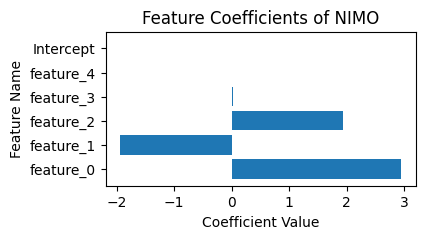

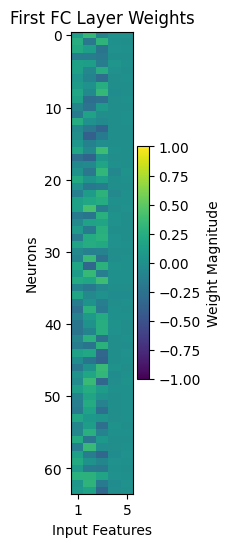

In [179]:
## Train our NIMO model and compare the results
expr_name = "ar_reg_setting1_wo_noise_check_local_explain"

hybrid_pred = torch.load(f"../ckpts/predictions_{expr_name}.pt")[0]
pred_hybrid = np.array(hybrid_pred)

mse = mean_squared_error(test_df["target"], pred_hybrid)
print(f"MSE: {mse:.3f}")


model_ckpt = "../tb_logs/ar_reg_setting1_wo_noise_check_local_explain/version_0/checkpoints/best_model_epoch=740.ckpt"

model = AdaptiveRidgeRegression.load_from_checkpoint(model_ckpt)
print(model)

nimo_coeff = plot_nimo(model_ckpt, train_df, figsize1=(4, 2), figsize2=(1, 6))

In [186]:
# effect_0 = 3 * (2*sigmoid(X_test[:, 1]*X_test[:, 2])) * X_test[:, 0]
# effect_1 = -2 * X_test[:, 1]
# effect_2 = 2 * X_test[:, 2]
# effect_3 = 0 * X_test[:, 3]
# effect_4 = 0 * X_test[:, 4]

effect_0 = 2 * sigmoid(X_test[:, 1] * X_test[:, 2])
effect_1 = np.ones_like(X_test[:, 1])
effect_2 = np.ones_like(X_test[:, 2])
effect_3 = np.ones_like(X_test[:, 3])
effect_4 = np.ones_like(X_test[:, 4])

In [187]:
beta = model.beta.detach().cpu().numpy()
beta_0 = model.beta_0.detach().cpu().numpy()

model.eval()
with torch.no_grad():
    B_u = model.build_B_u(torch.tensor(X_test, dtype=torch.float32).to("cuda"))

print(beta)
print(B_u.shape)

[ 2.9498825  -1.9477843   1.9391503   0.02275567  0.00318205]
torch.Size([100, 5])


In [188]:
# learned_effect_0 = B_u[:, 0].cpu().numpy() * beta[0]
# learned_effect_1 = B_u[:, 1].cpu().numpy() * beta[1]
# learned_effect_2 = B_u[:, 2].cpu().numpy() * beta[2]
# learned_effect_3 = B_u[:, 3].cpu().numpy() * beta[3]
# learned_effect_4 = B_u[:, 4].cpu().numpy() * beta[4]

learned_effect_0 = B_u[:, 0].cpu().numpy() / X_test[:, 0]  # * beta[0]
learned_effect_1 = B_u[:, 1].cpu().numpy() / X_test[:, 1]  # * beta[1]
learned_effect_2 = B_u[:, 2].cpu().numpy() / X_test[:, 2]  # * beta[2]
learned_effect_3 = B_u[:, 3].cpu().numpy() / X_test[:, 3]  # * beta[3]
learned_effect_4 = B_u[:, 4].cpu().numpy() / X_test[:, 4]  # * beta[4]

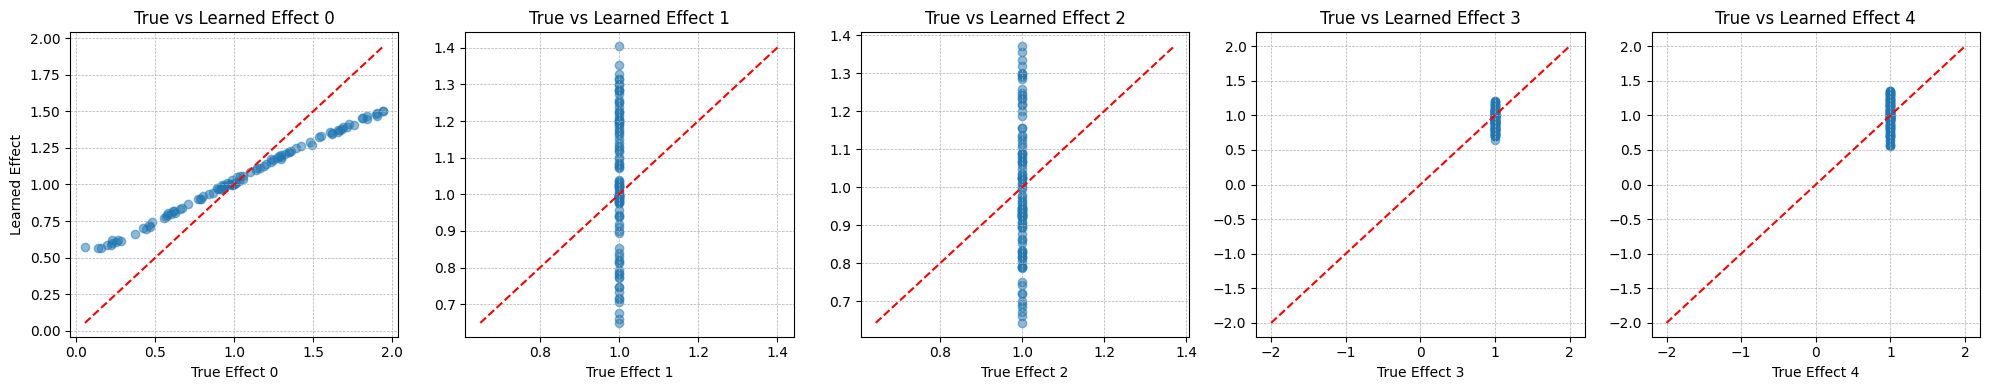

: 

In [ ]:
# plot 5 scatter plots in a row
fig, axes = plt.subplots(1, 5, figsize=(20, 4))
effects = [effect_0, effect_1, effect_2, effect_3, effect_4]
learned = [
    learned_effect_0,
    learned_effect_1,
    learned_effect_2,
    learned_effect_3,
    learned_effect_4,
]

for i, ax in enumerate(axes):
    x = effects[i]
    y = learned[i]
    ax.scatter(x, y, alpha=0.5)
    ax.set_xlabel(f"True Effect {i}")
    if i == 0:
        ax.set_ylabel("Learned Effect")
    ax.set_title(f"True vs Learned Effect {i}")
    mn = min(np.min(x), np.min(y))
    mx = max(np.max(x), np.max(y))

    if i >= 3:
        mn = -2
        mx = 2
    ax.plot([mn, mx], [mn, mx], color="red", linestyle="--")
    ax.grid(True, linestyle="--", linewidth=0.5)

plt.tight_layout()
plt.savefig(f"../nimo_local_explain_scatter_setting1.pdf", dpi=300)
plt.show()

### Boston Housing

In [166]:
train_df = pd.read_csv("../data/boston_2/train.csv")
val_df = pd.read_csv("../data/boston_2/val.csv")
test_df = pd.read_csv("../data/boston_2/test.csv")

X_train = train_df.drop(columns=["target"]).values
y_train = train_df["target"].values.astype(float)
X_val = val_df.drop(columns=["target"]).values
y_val = val_df["target"].values.astype(float)
X_test = test_df.drop(columns=["target"]).values
y_test = test_df["target"].values.astype(float)

In [160]:
train_df.shape, val_df.shape, test_df.shape

((303, 14), (101, 14), (102, 14))

==> training with noise_injection=False
AdaptiveRidgeRegression(
  (fc1): Linear(in_features=17, out_features=64, bias=True)
  (fc2): Linear(in_features=68, out_features=128, bias=True)
  (fc3): Linear(in_features=196, out_features=1, bias=True)
  (dropout2): Identity()
)
==> training with noise_injection=False
[-0.03237752  0.00914199 -0.05200826  0.07115339 -0.          0.285845
 -0.07274994 -0.2768911   0.28749105 -0.0766243  -0.11038455  0.04337269
 -0.1887033 ] [0.]


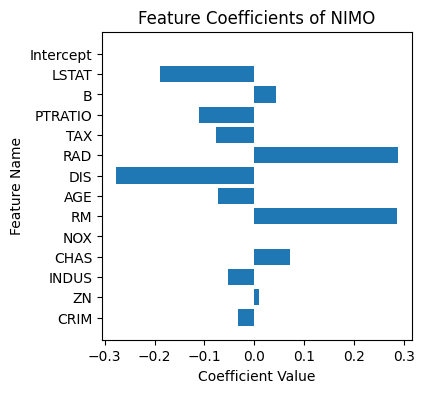

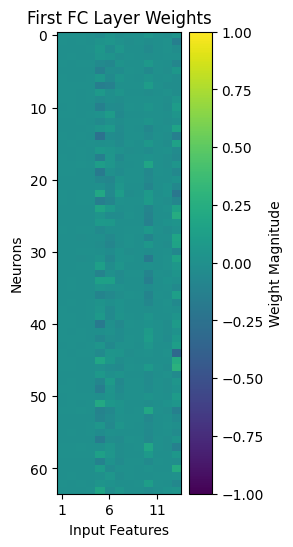

In [ ]:
ckpt_dir = f"../tb_logs/ar_reg_boston_2_lp_0.15/version_0/checkpoints/"
ckpt_files = glob.glob(os.path.join(ckpt_dir, "*.ckpt"))
model_ckpt = ckpt_files[0]

model = AdaptiveRidgeRegression.load_from_checkpoint(model_ckpt)
print(model)

nimo_coeff = plot_nimo(model_ckpt, train_df, figsize1=(4, 4), figsize2=(2, 6))

In [ ]:
model.eval().to("cuda")


def predict_fn(X_numpy):
    X_tensor = torch.tensor(X_numpy, dtype=torch.float32).to("cuda")
    with torch.no_grad():
        B_u = model.build_B_u(X_tensor)
        preds = model.forward(B_u)
    return preds.cpu().numpy()


X_train = train_df.drop(columns="target")
X_test = test_df.drop(columns="target")

explainer = shap.Explainer(predict_fn, X_train.values)
shap_values = explainer(X_test.values)

shap_matrix = shap_values.values
shap_bias = shap_values.base_values

print(shap_matrix.shape, shap_bias.shape)

(102, 13) (102,)


In [164]:
shap_matrix

array([[-0.01090607, -0.00148539, -0.03733838, ..., -0.07780997,
         0.01810894,  0.36159294],
       [ 0.01415538, -0.00413657, -0.08448744, ...,  0.10866652,
        -0.00689007,  0.06517287],
       [ 0.01955283,  0.02863097,  0.03800782, ..., -0.04031933,
         0.02737954,  0.33356405],
       ...,
       [ 0.01889676, -0.00312935, -0.06076625, ..., -0.13569501,
         0.00895031, -0.20993471],
       [ 0.01879135,  0.01831935,  0.04495025, ...,  0.12666978,
         0.01013684,  0.29327091],
       [ 0.01861741, -0.00497941,  0.0227082 , ..., -0.0472415 ,
         0.01767555,  0.13609726]])

In [168]:
beta = model.beta.detach().cpu().numpy()
beta_0 = model.beta_0.detach().cpu().numpy()

model.eval()
with torch.no_grad():
    B_u = model.build_B_u(torch.tensor(X_test, dtype=torch.float32).to("cuda"))

print(beta, beta_0)
print(B_u.shape)

[-0.03237752  0.00914199 -0.05200826  0.07115339 -0.          0.285845
 -0.07274994 -0.2768911   0.28749105 -0.0766243  -0.11038455  0.04337269
 -0.1887033 ] [0.]
torch.Size([102, 13])


In [169]:
learned_effect_0 = B_u[:, 0].cpu().numpy() * beta[0]
learned_effect_1 = B_u[:, 1].cpu().numpy() * beta[1]
learned_effect_2 = B_u[:, 2].cpu().numpy() * beta[2]
learned_effect_3 = B_u[:, 3].cpu().numpy() * beta[3]
learned_effect_4 = B_u[:, 4].cpu().numpy() * beta[4]
learned_effect_5 = B_u[:, 5].cpu().numpy() * beta[5]
learned_effect_6 = B_u[:, 6].cpu().numpy() * beta[6]
learned_effect_7 = B_u[:, 7].cpu().numpy() * beta[7]
learned_effect_8 = B_u[:, 8].cpu().numpy() * beta[8]
learned_effect_9 = B_u[:, 9].cpu().numpy() * beta[9]
learned_effect_10 = B_u[:, 10].cpu().numpy() * beta[10]
learned_effect_11 = B_u[:, 11].cpu().numpy() * beta[11]
learned_effect_12 = B_u[:, 12].cpu().numpy() * beta[12]

In [170]:
shap_matrix[:, 0]

array([-0.01090607,  0.01415538,  0.01955283,  0.0209781 , -0.09980378,
        0.01449474,  0.02096037,  0.019241  , -0.2312942 ,  0.01290926,
        0.01910012,  0.02036503,  0.01872959,  0.0065917 , -0.07321377,
        0.02169102,  0.02136424, -0.03444948, -0.08813425, -0.03696818,
        0.01966839,  0.01809056,  0.01887071,  0.00090912, -0.04343622,
        0.0163835 ,  0.01495803,  0.01916134,  0.02045795,  0.01872372,
       -0.03810416,  0.02092626,  0.01879668,  0.01749743, -0.12688982,
        0.01032056, -0.03286531, -0.00046816,  0.02028882,  0.01883755,
        0.01936181,  0.0158417 ,  0.0198689 , -0.12848765, -0.00778878,
       -0.02899501,  0.02033894, -0.01173825,  0.01766682, -0.07722341,
        0.02005867,  0.01901674, -0.21756821,  0.01948813, -0.04165957,
        0.01536025,  0.0217847 ,  0.01904513,  0.01820259,  0.02149999,
        0.02253234,  0.0174238 ,  0.02099021,  0.02061448,  0.01854366,
        0.01805556,  0.02091338,  0.01683573, -0.02669341,  0.01

In [171]:
learned_effect_0

array([-0.01401446,  0.01314823,  0.00927098,  0.01734743, -0.10892063,
        0.0143232 ,  0.01993288,  0.0127355 , -0.2709545 ,  0.0120081 ,
        0.01502831,  0.01272603,  0.00786592,  0.00670366, -0.07815511,
        0.01782884,  0.02240631, -0.03812926, -0.0964302 , -0.04151466,
        0.01717601,  0.01160842,  0.02009897,  0.00036814, -0.04936884,
        0.01682417,  0.0149851 ,  0.01610513,  0.01357327,  0.00922737,
       -0.03078765,  0.01925898,  0.00626005,  0.00489194, -0.14130855,
        0.00915554, -0.03677743, -0.00068422,  0.01727621,  0.01147291,
        0.01410505,  0.01634426,  0.01843123, -0.13780977, -0.00773297,
       -0.0328223 ,  0.01523509, -0.01288629,  0.01826558, -0.04821859,
        0.01544469,  0.01995753, -0.23367931,  0.0137971 , -0.05350372,
        0.01134717,  0.0227881 ,  0.01494649,  0.01850354,  0.02349784,
        0.02410375,  0.00601478,  0.0220087 ,  0.01784414,  0.01180309,
        0.0126162 ,  0.02156988,  0.01321092, -0.02967909,  0.00

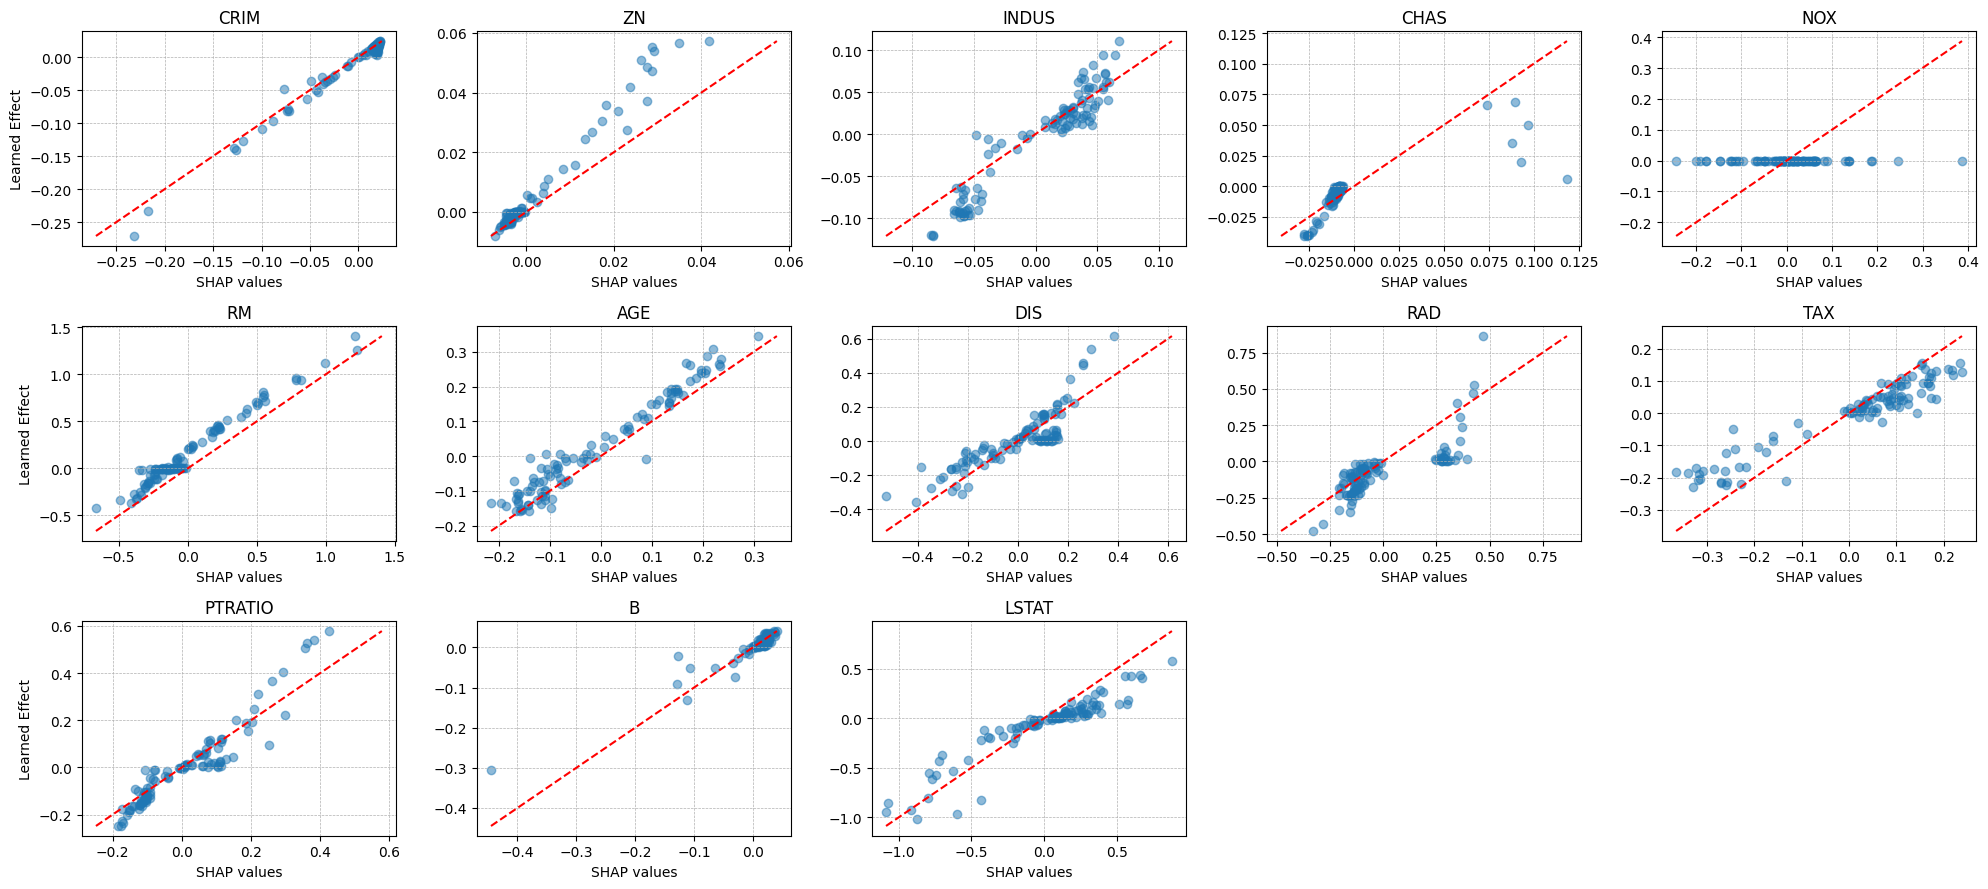

In [ ]:
# plot shap_matrix[:, 0] vs learned_effect_0 scatter plot
n_plots = 13
cols = 5
rows = (n_plots + cols - 1) // cols

learned_list = [
    learned_effect_0,
    learned_effect_1,
    learned_effect_2,
    learned_effect_3,
    learned_effect_4,
    learned_effect_5,
    learned_effect_6,
    learned_effect_7,
    learned_effect_8,
    learned_effect_9,
    learned_effect_10,
    learned_effect_11,
    learned_effect_12,
]

fig, axes = plt.subplots(rows, cols, figsize=(cols * 4, rows * 3))
axes = axes.flatten()

feats = [
    "CRIM",
    "ZN",
    "INDUS",
    "CHAS",
    "NOX",
    "RM",
    "AGE",
    "DIS",
    "RAD",
    "TAX",
    "PTRATIO",
    "B",
    "LSTAT",
]

for i in range(n_plots):
    x = shap_matrix[:, i]
    y = learned_list[i]
    ax = axes[i]
    ax.scatter(x, y, alpha=0.5)
    ax.set_xlabel(f"SHAP values")
    ax.set_ylabel("Learned Effect" if i % cols == 0 else "")
    ax.set_title(feats[i])
    mn = min(np.nanmin(x), np.nanmin(y))
    mx = max(np.nanmax(x), np.nanmax(y))
    ax.plot([mn, mx], [mn, mx], color="red", linestyle="--")
    ax.grid(True, linestyle="--", linewidth=0.5)

# turn off any extra axes
for j in range(n_plots, len(axes)):
    axes[j].axis("off")

plt.tight_layout()
plt.savefig(f"../boston_shap_vs_learned_effect_grid.pdf", dpi=300, bbox_inches="tight")

# plt.figure(figsize=(6, 6))
# plt.scatter(shap_matrix[:, 0], learned_effect_0, alpha=0.5)
# plt.xlabel('SHAP values for feature 0')
# plt.ylabel('Learned Effect for feature 0')
# plt.title('SHAP values vs Learned Effect for feature 0')
# plt.grid(True, linestyle='--', linewidth=0.5)
# plt.savefig(f'../boston_shap_vs_learned_effect_feature0.pdf', dpi=300)
# plt.show()